# DSCI 552 – Homework 5

**Name:** Pooja Nandyappa Subashchandra  
**GitHub Username:** nandyapp-afk  
**USC ID:** 1768721225

In [1]:
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="The least populated class")

# Relative paths (forward slashes only)
AI_PATH = "data/AcuteInflammations/diagnosis.data"
CC_DIR = "data/CommunitiesAndCrime"

SEED = 0
N_TRAIN = 1495                      # Problem 2: first 1495 rows are the training set

## Problem 1 – Decision Trees as Interpretable Models

### 1(a)–(b) Load the Acute Inflammations data and build a decision tree on the whole data set

The data set is multi-label: two binary decisions (inflammation of the urinary bladder, nephritis of renal pelvis origin) are given for every patient. The **label powerset** method is used: every combination of the two labels is treated as one class, which gives a single multiclass tree and one set of rules whose conclusions are the diagnoses. (Binary relevance would need two separate trees and ignores the dependence between the labels.)
The four classes are `neither`, `bladder` (inflammation of the urinary bladder only), `nephritis` (nephritis of renal pelvis origin only) and `both`. The yes/no symptoms are coded 1 = yes and 0 = no.

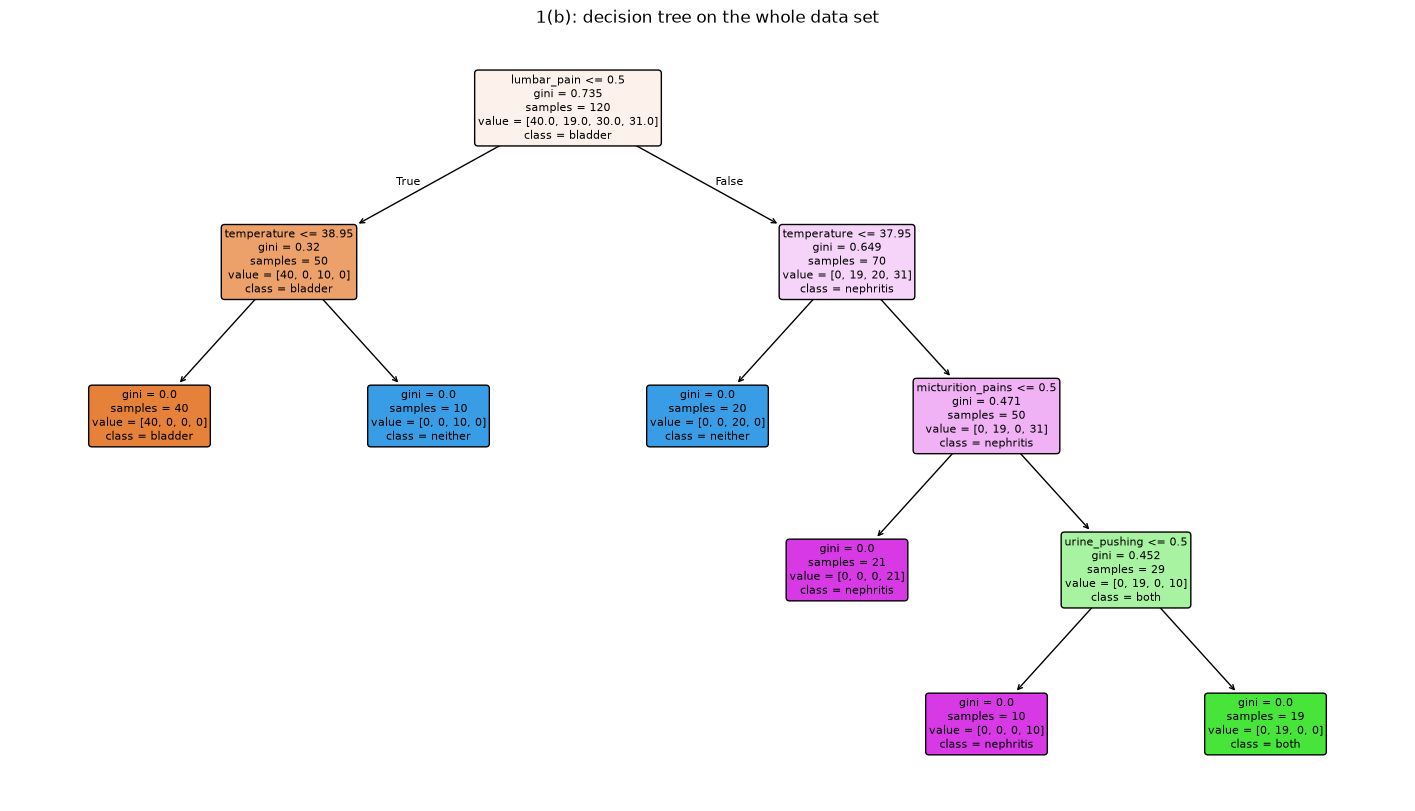

In [2]:
SYMPTOMS = ["nausea", "lumbar_pain", "urine_pushing", "micturition_pains", "burning_urethra"]
FEATURE_NAMES = ["temperature"] + SYMPTOMS

with open(AI_PATH, "rb") as f:
    encoding = "utf-16" if f.read(2) in (b"\xff\xfe", b"\xfe\xff") else "latin-1"
raw_ai = pd.read_csv(AI_PATH, sep="\t", header=None, dtype=str, encoding=encoding)
raw_ai = raw_ai.dropna(how="all").dropna(axis=1, how="all")
raw_ai.columns = FEATURE_NAMES + ["bladder_inflammation", "nephritis"]

yes_no = raw_ai.drop(columns="temperature").apply(lambda c: c.str.strip().map({"yes": 1, "no": 0}))
X_ai = pd.concat([raw_ai["temperature"].str.replace(",", ".").astype(float), yes_no[SYMPTOMS]], axis=1)

LABELS = {(0, 0): "neither", (1, 0): "bladder", (0, 1): "nephritis", (1, 1): "both"}
y_ai = np.array([LABELS[(a, b)] for a, b in zip(yes_no["bladder_inflammation"], yes_no["nephritis"])])

tree = DecisionTreeClassifier(random_state=SEED).fit(X_ai, y_ai)

plt.figure(figsize=(18, 10))
plot_tree(tree, feature_names=FEATURE_NAMES, class_names=list(tree.classes_),
          filled=True, rounded=True, fontsize=8)
plt.title("1(b): decision tree on the whole data set")
plt.show()

### 1(c) Decision rules as IF-THEN rules

Every path from the root to a leaf is one rule (conditions on the same feature are merged into one). The yes/no symptoms are written as `= yes` / `= no`, and `n` is the number of instances in the leaf.

In [3]:
def tree_to_rules(clf, feature_names):
    """Print one IF-THEN rule per leaf; conditions on the same feature are merged."""
    t = clf.tree_
    rules = []

    def walk(node, bounds):
        if t.children_left[node] == -1:                                   # leaf
            label = clf.classes_[np.argmax(t.value[node][0])]
            rules.append((bounds, label, int(t.n_node_samples[node])))
            return
        name, thr = feature_names[t.feature[node]], t.threshold[node]
        lo, hi = bounds.get(name, (-np.inf, np.inf))
        walk(t.children_left[node], {**bounds, name: (lo, min(hi, thr))})    # feature <= thr
        walk(t.children_right[node], {**bounds, name: (max(lo, thr), hi)})   # feature > thr

    def describe(name, lo, hi):
        if name in SYMPTOMS:                                              # yes/no symptoms (1 / 0)
            return f"{name} = " + ("yes" if lo >= 0.5 else "no")
        if lo == -np.inf:
            return f"{name} <= {hi:.2f}"
        if hi == np.inf:
            return f"{name} > {lo:.2f}"
        return f"{lo:.2f} < {name} <= {hi:.2f}"

    walk(0, {})
    for i, (bounds, label, n) in enumerate(rules, start=1):
        conditions = [describe(k, lo, hi) for k, (lo, hi) in bounds.items()]
        print(f"Rule {i}: IF " + (" AND ".join(conditions) or "TRUE") + f" THEN {label}   (n = {n})")


tree_to_rules(tree, FEATURE_NAMES)

Rule 1: IF lumbar_pain = no AND temperature <= 38.95 THEN bladder   (n = 40)
Rule 2: IF lumbar_pain = no AND temperature > 38.95 THEN neither   (n = 10)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN neither   (n = 20)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no THEN nephritis   (n = 21)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN nephritis   (n = 10)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN both   (n = 19)


### 1(d) Cost-complexity pruning

For every value of the pruning parameter α on the cost-complexity pruning path, the stratified 5-fold cross-validation accuracy of the pruned tree is computed. Among the trees whose accuracy is within one standard error of the best accuracy, the one with the largest α (the smallest tree) is selected, since it is the most interpretable one without a meaningful loss of accuracy.

Selected alpha = 0.0000: 6 leaves (full tree: 6 leaves), 5-fold CV accuracy = 0.992


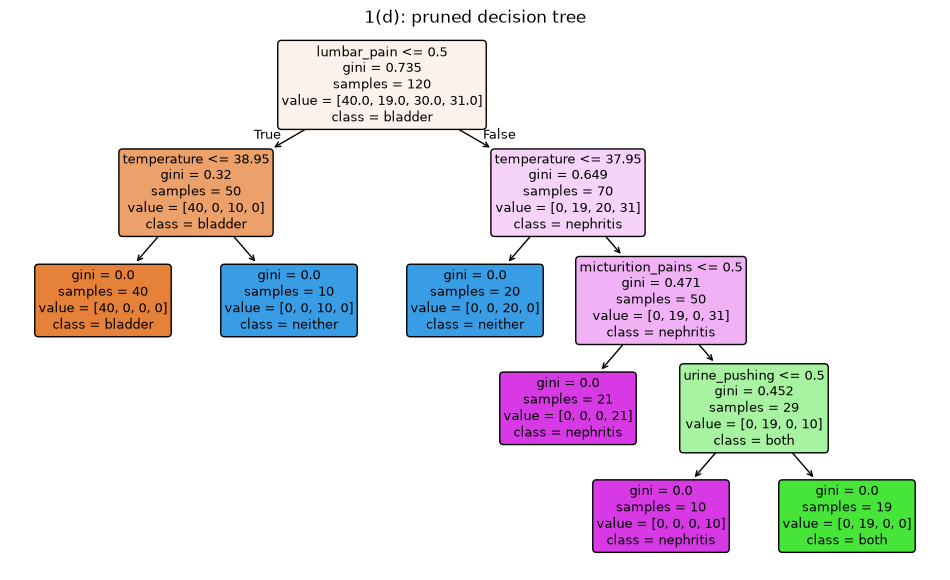

Rule 1: IF lumbar_pain = no AND temperature <= 38.95 THEN bladder   (n = 40)
Rule 2: IF lumbar_pain = no AND temperature > 38.95 THEN neither   (n = 10)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN neither   (n = 20)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no THEN nephritis   (n = 21)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN nephritis   (n = 10)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN both   (n = 19)


In [4]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
path = DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(X_ai, y_ai)
alphas = path.ccp_alphas[:-1]                    # the last alpha prunes the tree down to the root

means, ses = [], []
for a in alphas:
    s = cross_val_score(DecisionTreeClassifier(random_state=SEED, ccp_alpha=a), X_ai, y_ai, cv=skf)
    means.append(s.mean())
    ses.append(s.std(ddof=1) / np.sqrt(len(s)))
means, ses = np.array(means), np.array(ses)

best = means.argmax()
chosen = np.where(means >= means[best] - ses[best])[0].max()
pruned = DecisionTreeClassifier(random_state=SEED, ccp_alpha=alphas[chosen]).fit(X_ai, y_ai)
print(f"Selected alpha = {alphas[chosen]:.4f}: {pruned.get_n_leaves()} leaves "
      f"(full tree: {tree.get_n_leaves()} leaves), 5-fold CV accuracy = {means[chosen]:.3f}")

plt.figure(figsize=(12, 7))
plot_tree(pruned, feature_names=FEATURE_NAMES, class_names=list(pruned.classes_),
          filled=True, rounded=True, fontsize=9)
plt.title("1(d): pruned decision tree")
plt.show()
tree_to_rules(pruned, FEATURE_NAMES)

## Problem 2 – The LASSO and Boosting for Regression

### 2(a)–(b) Load the Communities and Crime data, split, and impute missing values

The first 1495 rows form the training set and the remaining rows the test set. The five non-predictive attributes (`state`, `county`, `community`, `communityname`, `fold`) are ignored, and the last column (`ViolentCrimesPerPop`) is the response.
Missing values (`?`) are replaced by **mean imputation**: the column means are computed on the training set only and applied to both sets.

In [5]:
def read_names(path):
    """Attribute names from the '@attribute <name> <type>' lines of communities.names."""
    with open(path, errors="ignore") as f:
        return [m.group(1) for m in (re.match(r"^@attribute\s+(\w+)\s", line) for line in f) if m]


names = read_names(f"{CC_DIR}/communities.names")
if len(names) != 128:
    print(f"Warning: found {len(names)} attribute names instead of 128, using generic names")
    names = [f"x{i}" for i in range(128)]
raw_cc = pd.read_csv(f"{CC_DIR}/communities.data", header=None, names=names, na_values="?")

X_raw = raw_cc.iloc[:, 5:-1]                     # 122 predictive attributes
y_cc = raw_cc.iloc[:, -1]                        # ViolentCrimesPerPop

imputer = SimpleImputer(strategy="mean").fit(X_raw.iloc[:N_TRAIN])
X_all = pd.DataFrame(imputer.transform(X_raw), columns=X_raw.columns)
X_train, X_test = X_all.iloc[:N_TRAIN], X_all.iloc[N_TRAIN:]
y_train, y_test = y_cc.iloc[:N_TRAIN], y_cc.iloc[N_TRAIN:]

print(f"Missing values before imputation: {int(X_raw.isna().sum().sum())} "
      f"(in {int((X_raw.isna().sum() > 0).sum())} columns); after: {int(X_all.isna().sum().sum())}")
print(f"Features: {X_all.shape[1]}   training rows: {len(X_train)}   test rows: {len(X_test)}")

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)


def test_mse(model, X):
    return mean_squared_error(y_test, model.predict(X))

Missing values before imputation: 36851 (in 23 columns); after: 0
Features: 122   training rows: 1495   test rows: 499


### 2(c) Correlation matrix of the features

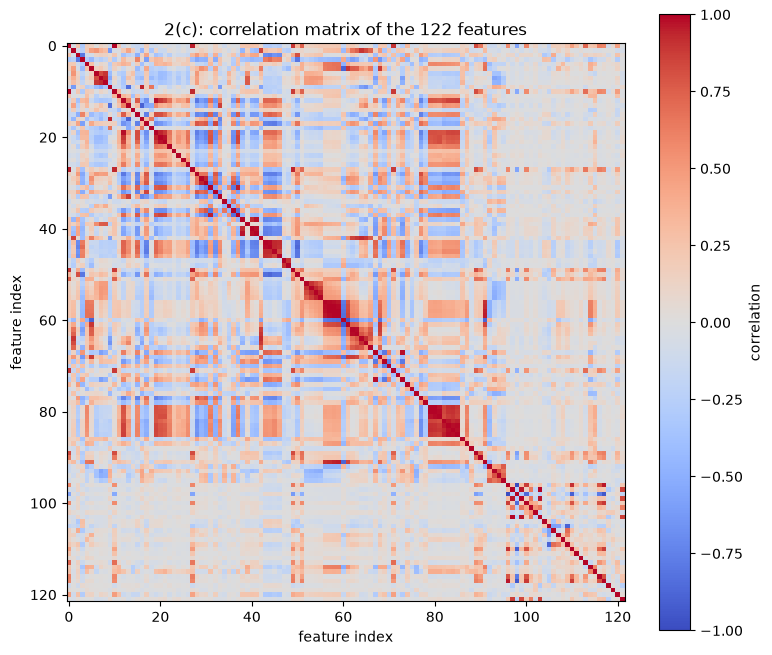

In [6]:
corr = X_all.corr()
plt.figure(figsize=(9, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="correlation")
plt.xlabel("feature index")
plt.ylabel("feature index")
plt.title("2(c): correlation matrix of the 122 features")
plt.show()

### 2(d) Coefficient of variation of each feature

CV = s / m, with s the sample standard deviation and m the sample mean of the feature (all rows, after imputation).

In [7]:
cv = (X_all.std() / X_all.mean()).replace([np.inf, -np.inf], np.nan)
pd.set_option("display.max_rows", 130)
cv.sort_values(ascending=False).rename("CV").to_frame()

,CV
NumStreet,4.407702
NumInShelters,3.485481
NumIlleg,2.994196
NumImmig,2.900497
LemasPctOfficDrugUn,2.555266
NumUnderPov,2.304970
population,2.203503
numbUrban,2.001744
HousVacant,1.958780
LandArea,1.678031


### 2(e) The ⌊√128⌋ = 11 features with the highest CV

Scatter plots (feature against the response `ViolentCrimesPerPop`) and box plots.

Features with the highest CV: ['NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'numbUrban', 'HousVacant', 'LandArea', 'racePctHisp']


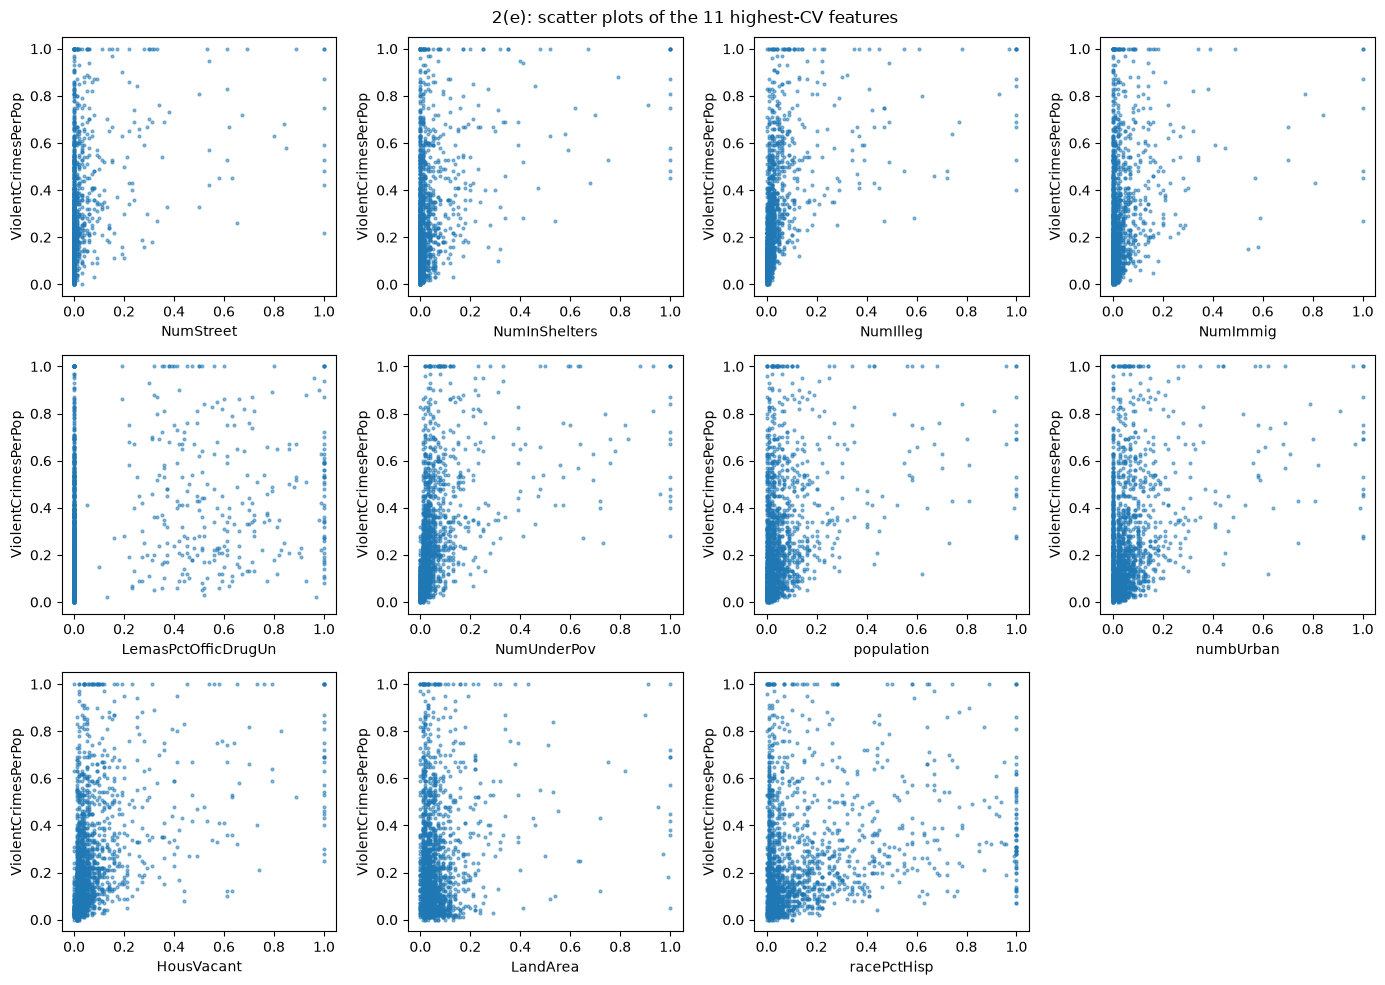

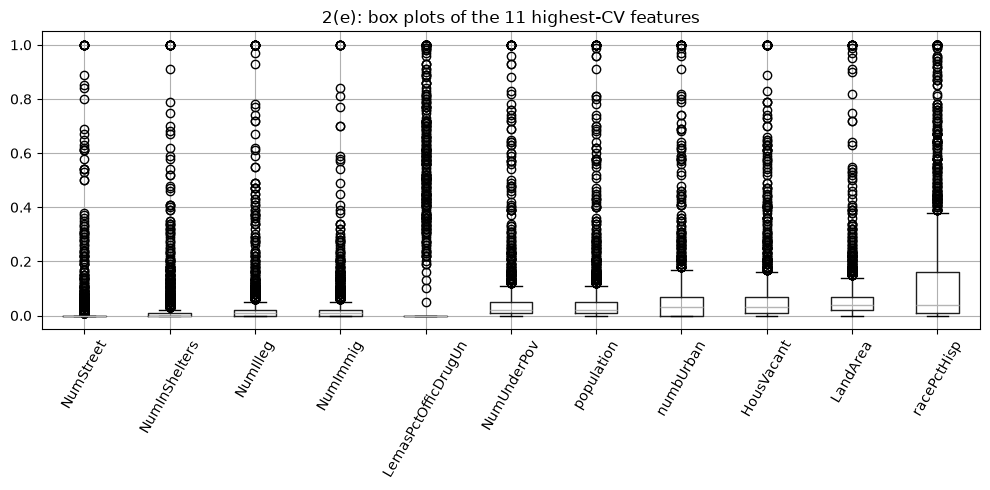

In [8]:
top = list(cv.nlargest(int(np.floor(np.sqrt(128)))).index)
print("Features with the highest CV:", top)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, f in zip(axes.ravel(), top):
    ax.scatter(X_all[f], y_cc, s=4, alpha=0.5)
    ax.set_xlabel(f)
    ax.set_ylabel("ViolentCrimesPerPop")
for ax in axes.ravel()[len(top):]:
    ax.axis("off")
fig.suptitle("2(e): scatter plots of the 11 highest-CV features")
plt.tight_layout()
plt.show()

ax = X_all[top].boxplot(figsize=(10, 5), rot=60)
ax.set_title("2(e): box plots of the 11 highest-CV features")
plt.tight_layout()
plt.show()

**Answer:** No. A scatter plot shows only the marginal relationship between one feature and the response, so it cannot establish statistical significance, which requires a hypothesis test (for example, the t-test of a regression coefficient). The 11 features are also strongly right-skewed, with most values near 0, so the points overlap and hide any trend. At most, a weak positive tendency is visible for some of them.

### 2(f) Linear model fitted by least squares

The test error is the mean squared error (MSE) on the test set.

In [9]:
ols = LinearRegression().fit(X_train, y_train)
print(f"Least squares: test MSE = {test_mse(ols, X_test):.5f}")

Least squares: test MSE = 0.01814


### 2(g) Ridge regression, λ chosen by 5-fold cross-validation

In [10]:
ridge = RidgeCV(alphas=np.logspace(-4, 2, 60), cv=kf, scoring="neg_mean_squared_error").fit(X_train, y_train)
print(f"Ridge: lambda = {ridge.alpha_:.4g}   test MSE = {test_mse(ridge, X_test):.5f}")

Ridge: lambda = 2.36   test MSE = 0.01760


### 2(h) LASSO, λ chosen by 5-fold cross-validation, with the original and with standardized features

The features of this data set are already normalized to [0, 1]. For the second fit they are standardized (zero mean, unit variance, using the training set statistics).

In [11]:
def fit_lasso(Xtr, Xte, columns, title):
    model = LassoCV(cv=kf, random_state=SEED, max_iter=50000).fit(Xtr, y_train)
    selected = list(columns[model.coef_ != 0])
    mse = mean_squared_error(y_test, model.predict(Xte))
    print(f"{title}: lambda = {model.alpha_:.4g}   test MSE = {mse:.5f}   selected variables: {len(selected)}")
    print(selected)
    return mse


scaler = StandardScaler().fit(X_train)
mse_orig = fit_lasso(X_train, X_test, X_train.columns, "LASSO, original features")
print()
mse_std = fit_lasso(scaler.transform(X_train), scaler.transform(X_test), X_train.columns,
                    "LASSO, standardized features")

LASSO, original features: lambda = 8.194e-05   test MSE = 0.01782   selected variables: 80
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'medFamInc', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMomYoungKids', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PersPerOwnOccHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPc

**Answer:** The test errors are practically identical (test MSE 0.01782 for the original features and 0.01784 for the standardized features), so standardization does not improve the prediction. It only changes the selected λ (8.2e-05 against 6.6e-04, because the penalty acts on coefficients of a different scale) and slightly changes the set of selected variables (80 against 76). This is expected, since the features of this data set are already normalized to [0, 1].

### 2(i) Principal component regression, M chosen by 5-fold cross-validation

Principal components are computed from the (already normalized) features and a least squares regression is fitted on the first M components; M = 1, …, 122 is cross-validated.

In [12]:
pcr = GridSearchCV(make_pipeline(PCA(), LinearRegression()),
                   {"pca__n_components": list(range(1, X_train.shape[1] + 1))},
                   cv=kf, scoring="neg_mean_squared_error").fit(X_train, y_train)
print(f"PCR: M = {pcr.best_params_['pca__n_components']}   test MSE = {test_mse(pcr, X_test):.5f}")

PCR: M = 96   test MSE = 0.01847


### 2(j) L1-penalized gradient boosting trees (XGBoost)

An XGBoost regression model is fitted with the L1 regularization term `reg_alpha` (α) on the leaf weights. α is chosen by 5-fold cross-validation over a grid; the other settings are fixed (200 trees, learning rate 0.1, maximum depth 3).

In [13]:
xgb = GridSearchCV(XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=SEED),
                   {"reg_alpha": [0, 0.01, 0.1, 1, 10, 100]},
                   cv=kf, scoring="neg_mean_squared_error").fit(X_train, y_train)
print(f"XGBoost: alpha = {xgb.best_params_['reg_alpha']}   test MSE = {test_mse(xgb, X_test):.5f}")

XGBoost: alpha = 0.1   test MSE = 0.01643
